In [10]:
from langgraph.graph import StateGraph , START , END

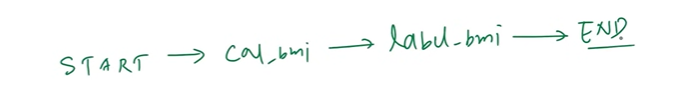

In [11]:
from typing import TypedDict

In [12]:
class BMIState(TypedDict):
    weight : float
    height : float
    bmi : float
    category : str

In [13]:
def calculate_bmi(state : BMIState) -> BMIState :
    weight = state['weight']
    height = state['height']
    
    bmi = weight / (height * height)
    # formula for bmi

    state['bmi'] = bmi
    # updating the state

    return state

def label_bmi(state : BMIState) -> BMIState :
    
    if state['weight'] < 40:
        state['category'] = "underweight" 
    elif state['weight'] > 100:
        state['category'] = "overweight"
    else: state['category'] = 'normal'
    
    return state



In [14]:
graph = StateGraph(BMIState)

# add nodes to the graph
# our workflow is input -> calculate bmi -> output
# therefore we only need one node

graph.add_node('calculate_bmi' , calculate_bmi)
graph.add_node('label_bmi' , label_bmi)
# when a node runs , it needs a function , this function always accepts the state , and whenever a node's function finishes its execution , it return the state


# add edges to the graph

# our graph looks like START --> calculate_bmi --> END
# START AND END ARE DUMMY NODES

graph.add_edge(START , 'calculate_bmi')
graph.add_edge( 'calculate_bmi' , 'label_bmi')
graph.add_edge('calculate_bmi' , END)




In [15]:
# compile the graph

workflow = graph.compile()

In [16]:
# execute the graph
initial_state = {'weight' : 80 , 'height' : 172}

final_state = workflow.invoke({'weight' : 80 , 'height' : 172})

In [17]:
final_state

{'weight': 80,
 'height': 172,
 'bmi': 0.0027041644131963224,
 'category': 'normal'}

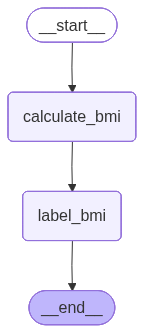

In [18]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())